# 08 · Predicting genomic alterations from tissue architecture (preliminary)

> **This notebook is a first, very preliminary exploration** (choice and definition of targets, model selection specific to each target, calibration, interpretation, etc.). Its results should be read as indicative only.

Does the image predict genomic alterations, and does it do so beyond what is already known without the image? Three alterations with clear footprints in notebook 06 (`genomic_alterations.alterations`): TP53 mutation (classification), tumour mutational burden and aneuploidy (regression, to avoid an arbitrary threshold).

Design, shared with notebook 07 (`genomic_prediction`): the same image features, the same held-out test sites, site-grouped cross-validation and preprocessing learned inside each training fold. Specific to this notebook (`genomic_alterations`):
- **Image model:** a fixed model family per task, the one that performed best in earlier exploratory analyses: logistic regression for TP53 (`classification_model`) and a random forest for the continuous targets (`regression_model`), whose values are mapped to a normal distribution by ranks inside each training fold. Hyperparameters, including the number of image features kept by univariate selection, are tuned by a randomised search (`n_iter`). Comparing model families per target is a next step.
- **Clinical baseline:** subtype, histology and purity (`base_features`), with a logistic or ridge regression.
- **Beyond subtype:** performance of the image model within each subtype.
- **Metrics:** AUC for TP53, Spearman correlation for the continuous targets (it measures how well patients are ranked, not the predicted values).

**Outputs**: tables in `results/<indication>/08_genomic_alteration_prediction/` and figures in `figures/<indication>/08_genomic_alteration_prediction/`.

## 0. Setup

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import shap

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_classif, f_regression
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.utils.class_weight import compute_sample_weight

from opentme_tcga import genomic_prediction as gp
from opentme_tcga.config import ensure_dirs, load_config
from opentme_tcga.genomic_footprints import select_image_features
from opentme_tcga.plotting import category_colors


INDICATION = "breast"          # name of a file in configs/indications/

cfg = load_config(INDICATION)
P = cfg["paths"]
GP, GA = cfg["genomic_prediction"], cfg["genomic_alterations"]
SUB = cfg["tcga_molecular"]["subtypes"]

OUT_DIR = P["results"] / "08_genomic_alteration_prediction"
FIGS = P["figures"] / "08_genomic_alteration_prediction"
ensure_dirs(cfg)
FIGS.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"

## 1. Configuration

In [2]:
SUBTYPE = SUB["column"]
PURITY = cfg["immune_phenotypes"]["molecular"]["purity"]
ALIASES = {"subtype": SUBTYPE, "purity": PURITY}
BASE_COLUMNS = [ALIASES.get(c, c) for c in GA["base_features"]]
GROUP, SEED = GP["group_column"], GP["seed"]
cv = GroupKFold(n_splits=GP["cv_folds"])
preprocessor = gp.make_preprocessor()

CLASSIFIERS = {"logistic": LogisticRegression(max_iter=5000),
               "random_forest": RandomForestClassifier(random_state=SEED, n_jobs=1)}
REGRESSORS = {"random_forest": RandomForestRegressor(random_state=SEED, n_jobs=1)}

## 2. Data, image features and held-out sites

Exactly as in notebook 07 (sections 2 and 3): the same image features, the same test sites (drawn with the same seed) and the same redundancy filter, so both notebooks are evaluated on the same patients. A tumour mutational burden of 0 in a tumour without mutation calls is missing data and is set to missing.

In [3]:
data = pd.read_parquet(P["integrated"])
if {"thor_tmb", "mut_profiled"} <= set(data.columns):
    data.loc[(data["thor_tmb"] == 0) & (data["mut_profiled"] != 1), "thor_tmb"] = np.nan

IMG = cfg["genomic_footprints"]["image"]
image_features = select_image_features(
    data, pq.read_schema(P["opentme_patients"]).names, drop_prefixes=IMG["drop_prefixes"],
    drop_substrings=IMG["drop_substrings"], drop_columns=IMG["drop_columns"] + GP["extra_drop_columns"],
    max_missing=IMG["max_missing"], max_dominant_fraction=IMG["max_dominant_fraction"],
)
split_data = data.dropna(subset=[GP["split_column"] or SUBTYPE, GROUP])
test_sites = gp.site_split(split_data, GROUP, GP["test_size"], SEED)
FEATURES = gp.drop_redundant(data[~data[GROUP].isin(test_sites)], image_features, GP["redundancy_threshold"])

counts = data[SUBTYPE].value_counts()
CLASSES = GP["classes"] or counts[counts >= GP["min_class_size"]].index.tolist()
COLORS = category_colors(CLASSES, SUB.get("colors"))
print(f"Image features: {len(FEATURES)} | test sites: {len(test_sites)} | subtypes: {CLASSES}")

Image features: 275 | test sites: 8 | subtypes: ['LumA', 'LumB', 'Basal', 'HER2E']


## 3. Targets and cross-validated performance

Number of patients with each target and the skewness of the continuous ones. Tumour mutational burden is extremely right-skewed (a few hypermutated tumours), hence the rank-based mapping of the target and the Spearman metric.

In [4]:
display(pd.DataFrame([{"alteration": a["name"], "column": a["column"], "task": a["task"],
                       "n_available": int(data[a["column"]].notna().sum()),
                       "skewness": data[a["column"]].skew() if a["task"] == "regression" else np.nan}
                      for a in GA["alterations"] if a["column"] in data.columns]).round(2))

,alteration,column,task,n_available,skewness
0,TP53 mutation,mut_TP53,classification,956,NaN
1,Tumour mutational burden,thor_tmb,regression,944,13.49
2,Aneuploidy,thor_aneuploidy_score,regression,974,0.43


In [5]:
def quantile_target(regressor):
    # Continuous target mapped to a normal distribution by ranks, learned on the training folds only
    return TransformedTargetRegressor(regressor=regressor,
                                      transformer=QuantileTransformer(output_distribution="normal", n_quantiles=500))


rows, alteration_models = [], {}
for alt in GA["alterations"]:
    name, column, is_clf = alt["name"], alt["column"], alt["task"] == "classification"
    if column not in data.columns:
        print(f"{name}: column {column} not found, skipped")
        continue
    d = data.dropna(subset=[column])
    d_train = d[~d[GROUP].isin(test_sites)]
    y = d_train[column].astype(int) if is_clf else d_train[column]
    g = d_train[GROUP]

    if is_clf:
        space = gp.parse_space(GP["search_spaces"][GA["classification_model"]])
        image = Pipeline([("preprocess", preprocessor), ("select", SelectKBest(f_classif)),
                          ("model", clone(CLASSIFIERS[GA["classification_model"]]))])
        base = Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])
        scoring, metric, fit_params = "roc_auc", roc_auc_score, {"model__sample_weight": compute_sample_weight("balanced", y)}
        prefix = ""
    else:
        space = gp.parse_space(GP["search_spaces"][GA["regression_model"]])
        image = quantile_target(Pipeline([("preprocess", preprocessor), ("select", SelectKBest(f_regression)),
                                          ("model", clone(REGRESSORS[GA["regression_model"]]))]))
        base = quantile_target(Pipeline([("preprocess", preprocessor), ("model", Ridge())]))
        scoring, metric, fit_params = gp.spearman_scorer, gp.spearman_score, {}
        prefix = "regressor__"
    space = {f"{prefix}{k}": v for k, v in {**space, "select__k": GA["select_k"]}.items()}

    search = RandomizedSearchCV(image, space, n_iter=GA["n_iter"], cv=cv, scoring=scoring,
                                random_state=SEED, n_jobs=-1)
    search.fit(d_train[FEATURES], y, groups=g, **fit_params)
    image_folds = gp.fold_scores(search)
    base_folds = cross_validate(base, d_train[BASE_COLUMNS], y, groups=g, cv=cv, scoring=scoring)["test_score"]

    # Out-of-fold image predictions and performance within each subtype
    oof = cross_val_predict(clone(search.best_estimator_), d_train[FEATURES], y, groups=g, cv=cv,
                            method="predict_proba" if is_clf else "predict", params=fit_params)
    oof = oof[:, 1] if is_clf else oof
    within = gp.score_within_groups(y, oof, d_train[SUBTYPE], metric, CLASSES, GA["min_per_subtype"],
                                    GA["min_per_class"] if is_clf else None)

    rows.append({"alteration": name, "metric": "AUC" if is_clf else "Spearman", "n_train": len(d_train),
                 "base_mean": np.mean(base_folds), "base_sd": np.std(base_folds),
                 "image_mean": np.mean(image_folds), "image_sd": np.std(image_folds),
                 **{f"within_{s}": v for s, v in within.items()}, "best_params": search.best_params_})
    alteration_models[name] = {"image": search.best_estimator_, "base": base, "column": column, "is_clf": is_clf,
                               "metric": metric}
    print(f"{name} done")

alteration_cv = pd.DataFrame(rows)
alteration_cv.to_csv(OUT_DIR / "alterations_cv_summary.csv", index=False)
display(alteration_cv.drop(columns="best_params").round(3))

TP53 mutation done
Tumour mutational burden done
Aneuploidy done


,alteration,metric,n_train,base_mean,base_sd,image_mean,image_sd,within_LumA,within_LumB,within_Basal,within_HER2E
0,TP53 mutation,AUC,674,0.869,0.030,0.848,0.038,0.702,0.679,0.467,0.721
1,Tumour mutational burden,Spearman,666,0.426,0.073,0.457,0.046,0.258,0.338,0.122,-0.053
2,Aneuploidy,Spearman,697,0.440,0.061,0.442,0.017,0.338,0.334,0.091,0.015


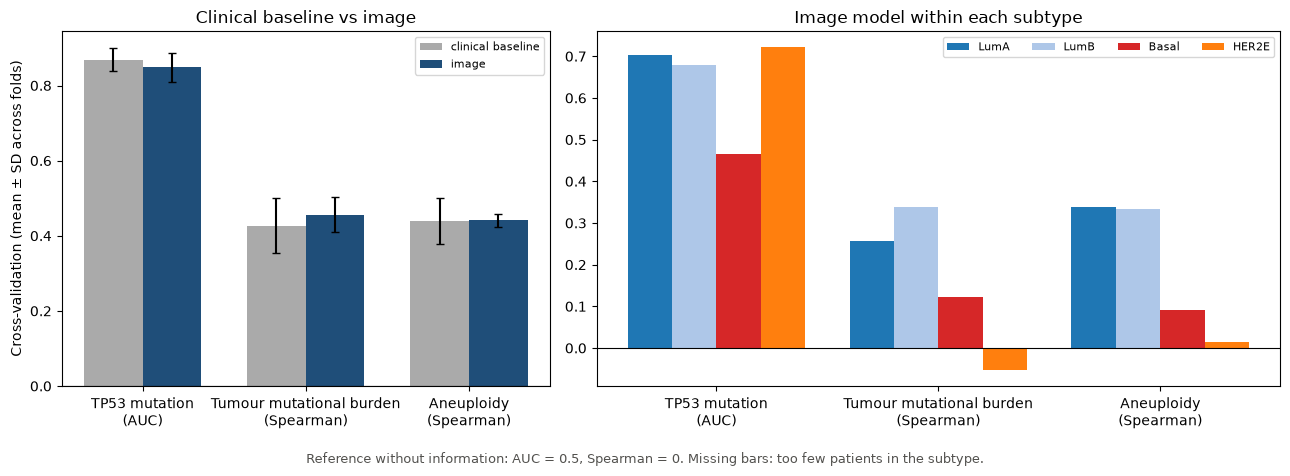

In [6]:
# Cross-validated performance: clinical baseline vs image, and the image model within each subtype
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(alteration_cv))
labels = [f"{a}\n({m})" for a, m in zip(alteration_cv["alteration"], alteration_cv["metric"])]
for offset, prefix, color, label in [(-0.18, "base", "#aaaaaa", "clinical baseline"), (0.18, "image", "#1f4e79", "image")]:
    axes[0].bar(x + offset, alteration_cv[f"{prefix}_mean"], width=0.36, yerr=alteration_cv[f"{prefix}_sd"],
                capsize=3, color=color, label=label)
axes[0].set_xticks(x, labels)
axes[0].set_ylabel("Cross-validation (mean ± SD across folds)")
axes[0].set_title("Clinical baseline vs image")
axes[0].legend(fontsize=8)

width = 0.8 / len(CLASSES)
for k, s in enumerate(CLASSES):
    axes[1].bar(x + (k - (len(CLASSES) - 1) / 2) * width, alteration_cv[f"within_{s}"], width=width,
                color=COLORS[s], label=s)
axes[1].set_xticks(x, labels)
axes[1].set_title("Image model within each subtype")
axes[1].legend(fontsize=8, ncol=len(CLASSES))
for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
fig.text(0.5, -0.04, "Reference without information: AUC = 0.5, Spearman = 0. Missing bars: too few patients in the subtype.",
         ha="center", fontsize=9, color="#52514e")
fig.tight_layout()
fig.savefig(FIGS / "alterations_cv.png", bbox_inches="tight")
plt.show()

**Observations (breast, preliminary)**
- Overall, the image alone performs like the clinical baseline (subtype, histology, purity) for the three alterations: the H&E does not add to what is known without it.
- Within subtypes, where subtype cannot drive the prediction, the image model still separates TP53-mutated from wild-type luminal and HER2-enriched tumours (AUC ≈ 0.7) and ranks aneuploidy among luminal tumours (Spearman ≈ 0.33), consistent with the nuclear-size features of the SHAP figure (section 4). Signal is weak or absent in basal-like tumours, which are almost uniformly TP53-mutated and unstable. HER2-enriched estimates rest on few patients.

## 4. Which image features do the models use?

SHAP values of each image model, computed on a sample of training patients (shap_max_patients): exact for the logistic regression of TP53 (LinearExplainer) and for the random forests of the continuous targets (TreeExplainer, on the rank-normal scale of the target). Bars show the mean |SHAP| of the most important features (shap_top), on the right if higher values of the feature raise the prediction (more likely mutated, higher burden or aneuploidy) and on the left if they lower it; for the random forests, the direction is the sign of the correlation between a feature and its SHAP values.

As in notebook 07, SHAP values are conditional on the other features and correlated features share their weight, so a single feature should be read as a representative of its group. Given the preliminary nature of these models, the figure shows what each model relies on, not established biology.

Image features used by each model: {'TP53 mutation': 200, 'Tumour mutational burden': 275, 'Aneuploidy': 275}


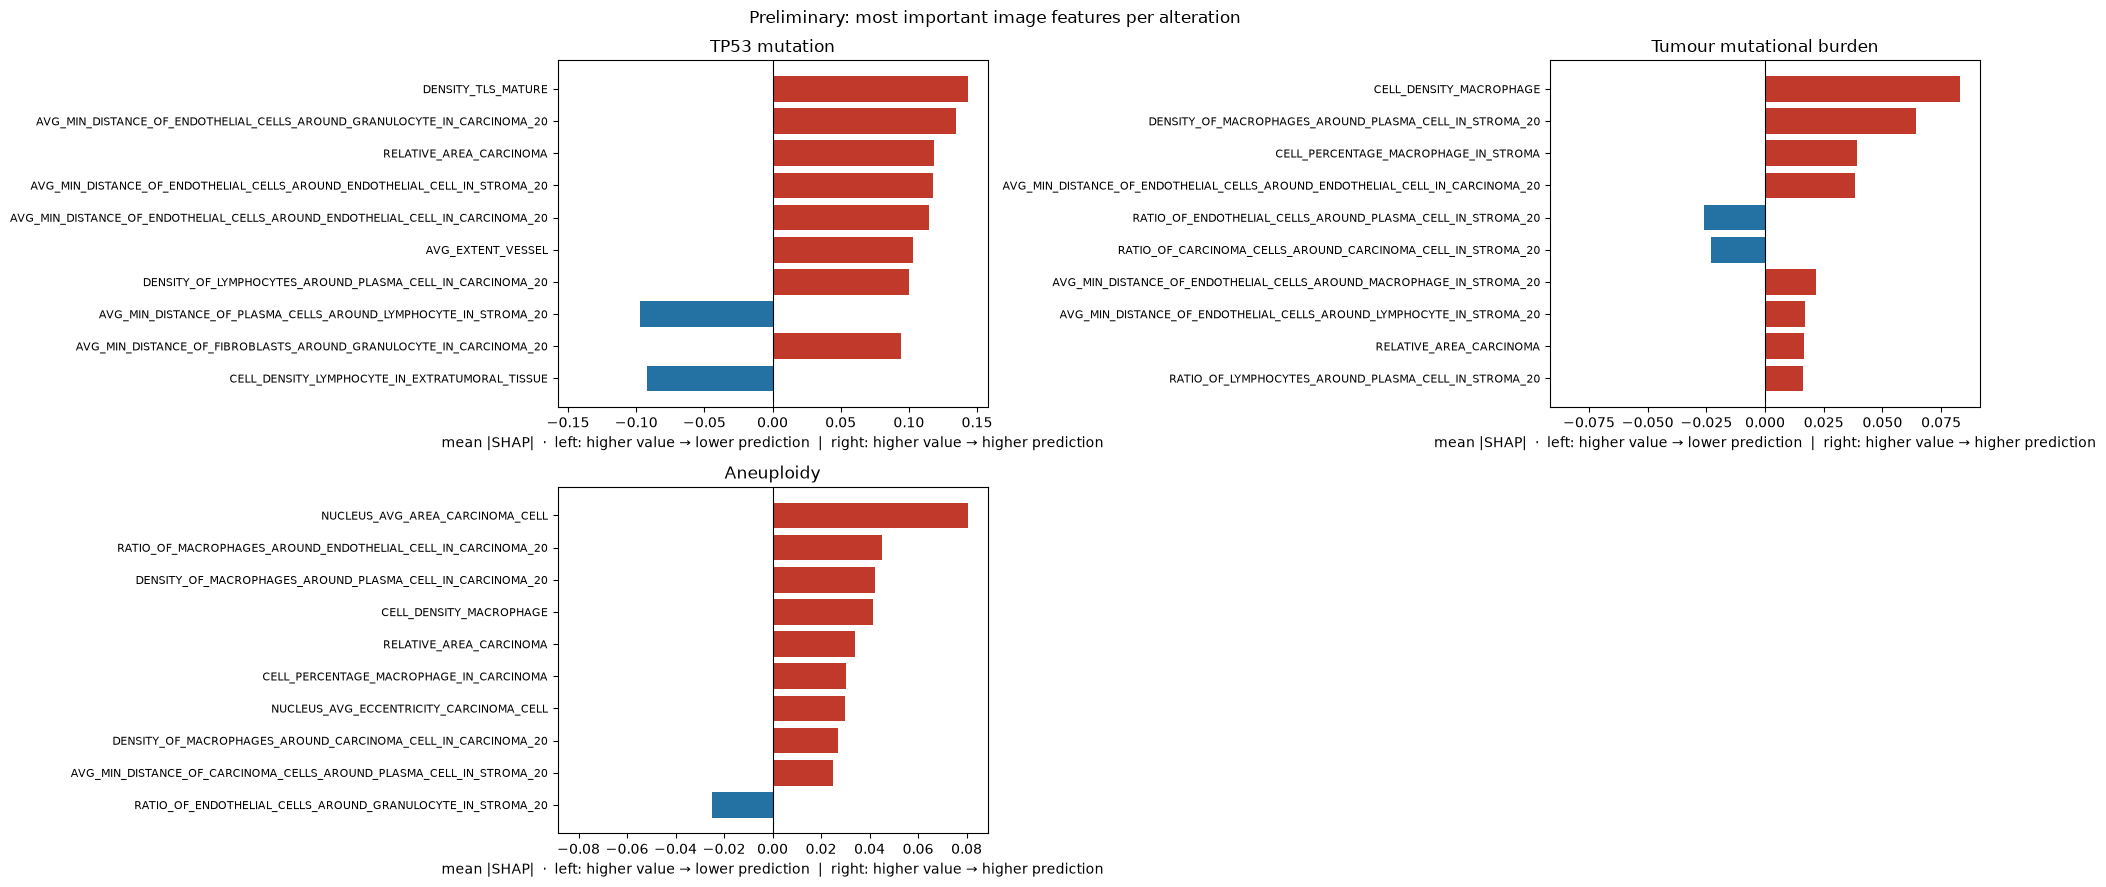

In [7]:
# SHAP of each image model (refitted on all training patients by the search), on a sample of training patients
shap_signed, shap_n = {}, {}
for name, m in alteration_models.items():
    column, is_clf = m["column"], m["is_clf"]
    d_train = data.dropna(subset=[column])
    d_train = d_train[~d_train[GROUP].isin(test_sites)]
    d_train = d_train.sample(min(len(d_train), GA["shap_max_patients"]), random_state=SEED)
    pipe = m["image"] if is_clf else m["image"].regressor_          # regression: model on the rank-normal target
    names = np.array(gp.feature_names_out(pipe))[pipe.named_steps["select"].get_support()]
    X_t = pd.DataFrame(pipe[:-1].transform(d_train[FEATURES]), columns=names)
    model = pipe.named_steps["model"]
    if isinstance(model, LogisticRegression):
        explainer = shap.LinearExplainer(model, shap.maskers.Independent(X_t, max_samples=len(X_t)))
        values = explainer(X_t).values
    else:
        values = shap.TreeExplainer(model)(X_t, check_additivity=False).values
    shap_signed[name] = gp.signed_importance(values, X_t)
    shap_n[name] = len(names)

shap_signed = pd.DataFrame(shap_signed).fillna(0)
shap_signed.to_csv(OUT_DIR / "alterations_shap_signed_importance.csv")
print("Image features used by each model:", shap_n)
fig = gp.plot_signed_importance(
    shap_signed, GA["shap_top"], title="Preliminary: most important image features per alteration",
    xlabel="mean |SHAP|  ·  left: higher value → lower prediction  |  right: higher value → higher prediction")
fig.savefig(FIGS / "alterations_shap_signed.png", bbox_inches="tight")
plt.show()

**Observations (breast, preliminary)**
- The image models do not include subtype, so these features may partly reflect subtype rather than the alteration itself.
- Aneuploidy: the most important feature is the average nucleus area of tumour cells (larger nuclei, higher aneuploidy), followed by nuclear eccentricity, consistent with aneuploid cells carrying more DNA (the hypothesis of notebook 06).
- TP53 mutation: the model relies mostly on the context of high-grade, immune-active tumours (mature TLS, lymphocytes around plasma cells, larger carcinoma regions), where TP53 mutations concentrate; this cannot be separated from a basal-like signature.
- Tumour mutational burden: small importances, mainly macrophage features; little to interpret, as expected from its weak prediction.

## 5. Final evaluation on the held-out sites

Each image model, refitted on all training patients by the search, and the clinical baseline, fitted now on all training patients, are evaluated once on the test patients. A paired bootstrap gives 95 % intervals for both models and for their difference; the image model is also evaluated within each subtype.

,alteration,base_mean,image_mean,metric,n_test,base_test,base_low,base_high,image_test,image_low,image_high,diff_low,diff_high,p_image_not_better,within_LumA,within_LumB,within_Basal,within_HER2E,diff
0,TP53 mutation,0.869,0.848,AUC,282,0.869,0.820,0.913,0.841,0.783,0.894,-0.087,0.023,0.850,0.661,0.803,NaN,NaN,-0.028
1,Tumour mutational burden,0.426,0.457,Spearman,278,0.351,0.243,0.446,0.389,0.276,0.481,-0.063,0.147,0.254,0.223,0.326,0.058,NaN,0.038
2,Aneuploidy,0.440,0.442,Spearman,277,0.359,0.259,0.459,0.340,0.230,0.440,-0.121,0.083,0.641,0.206,0.377,0.123,-0.026,-0.019


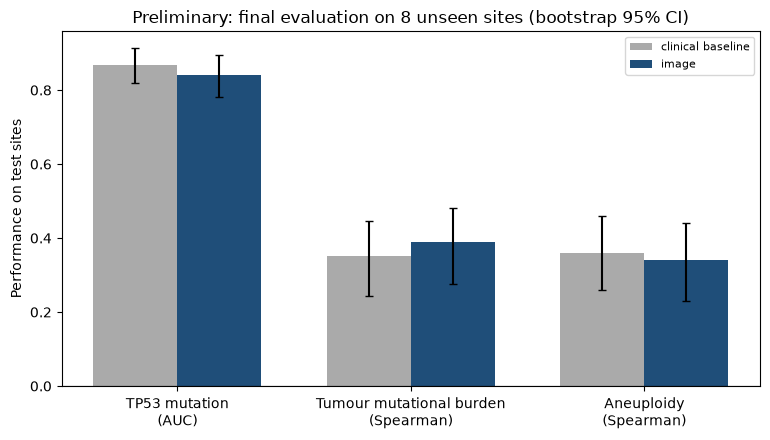

In [8]:
rows = []
for name, m in alteration_models.items():
    column, is_clf, metric = m["column"], m["is_clf"], m["metric"]
    d = data.dropna(subset=[column])
    d_train, d_test = d[~d[GROUP].isin(test_sites)], d[d[GROUP].isin(test_sites)]
    y_tr = d_train[column].astype(int) if is_clf else d_train[column]
    y_te = d_test[column].astype(int) if is_clf else d_test[column]

    base = clone(m["base"]).fit(d_train[BASE_COLUMNS], y_tr)
    if is_clf:
        p_image = m["image"].predict_proba(d_test[FEATURES])[:, 1]
        p_base = base.predict_proba(d_test[BASE_COLUMNS])[:, 1]
    else:
        p_image, p_base = m["image"].predict(d_test[FEATURES]), base.predict(d_test[BASE_COLUMNS])

    boot = gp.paired_bootstrap(y_te, p_image, p_base, metric, n_boot=GP["n_boot"], seed=SEED,
                               n_classes=2 if is_clf else 1)
    within = gp.score_within_groups(y_te, p_image, d_test[SUBTYPE], metric, CLASSES, GA["min_per_subtype"],
                                    GA["min_per_class"] if is_clf else None)
    rows.append({"alteration": name, "metric": "AUC" if is_clf else "Spearman", "n_test": len(d_test),
                 "base_test": metric(y_te, p_base), "base_low": boot["b_low"], "base_high": boot["b_high"],
                 "image_test": metric(y_te, p_image), "image_low": boot["a_low"], "image_high": boot["a_high"],
                 "diff_low": boot["diff_low"], "diff_high": boot["diff_high"], "p_image_not_better": boot["p_a_not_better"],
                 **{f"within_{s}": v for s, v in within.items()}})

alteration_test = pd.DataFrame(rows)
alteration_test["diff"] = alteration_test["image_test"] - alteration_test["base_test"]
alteration_test.to_csv(OUT_DIR / "alterations_test_summary.csv", index=False)
display(alteration_cv[["alteration", "base_mean", "image_mean"]].merge(alteration_test, on="alteration").round(3))

fig, ax = plt.subplots(figsize=(1.6 * len(alteration_test) + 3, 4.5))
x = np.arange(len(alteration_test))
for offset, prefix, color, label in [(-0.18, "base", "#aaaaaa", "clinical baseline"), (0.18, "image", "#1f4e79", "image")]:
    values = alteration_test[f"{prefix}_test"]
    errors = [values - alteration_test[f"{prefix}_low"], alteration_test[f"{prefix}_high"] - values]
    ax.bar(x + offset, values, width=0.36, yerr=errors, capsize=3, color=color, label=label)
ax.set_xticks(x, [f"{a}\n({m})" for a, m in zip(alteration_test["alteration"], alteration_test["metric"])])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Performance on test sites")
ax.set_title(f"Preliminary: final evaluation on {len(test_sites)} unseen sites (bootstrap 95% CI)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "alterations_test.png", bbox_inches="tight")
plt.show()

**Observations (breast, preliminary)**
- On 8 unseen sites, the image model performs like the clinical baseline for the three alterations (TP53 AUC 0.84 vs 0.87; TMB Spearman 0.39 vs 0.35; aneuploidy 0.34 vs 0.36); the bootstrap intervals of the differences include zero. TMB and aneuploidy are somewhat lower than in cross-validation for both models.
- Within luminal tumours the image signal reproduces on the test sites (TP53 AUC 0.66–0.80; aneuploidy Spearman 0.21–0.38), as in cross-validation, although these estimates rest on few patients.
- Next steps: a combined clinical + image model to measure the added value at equal subtype, target-specific model selection, and larger cohorts.